# EciGuía: asistente académico con RAG, agentes y MCP para la Escuela Colombiana de Ingeniería

**Proyecto final, IA Generativa (GELM) 2026-2.** Universidad Escuela Colombiana de Ingeniería Julio Garavito.

**Autor:** Marlio José Charry Espitia · Repositorio: [github.com/MarlioCharryECI/eciguia-gelm](https://github.com/MarlioCharryECI/eciguia-gelm)

EciGuía responde preguntas de estudiantes de pregrado sobre 13 documentos normativos de la Escuela, el calendario académico 2027, los valores de matrícula y derechos pecuniarios 2027 y el plan de estudios de Ingeniería de Sistemas. Cita el documento y la página de cada dato y dice "no encontré" cuando la respuesta no está en los documentos. Todo corre en local con modelos abiertos (Ollama), sin costo y sin enviar datos a terceros.

> **Cómo ejecutar este notebook.** Corre de principio a fin con *Restart & Run All*. Si Ollama está disponible (con `qwen2.5:7b`, `bge-m3` y el índice construido), las celdas de demostración llaman al modelo en vivo. Si no, cargan las salidas guardadas en `docs/resultados/`, así que el notebook también corre en un equipo sin GPU ni Ollama. La evaluación completa (5 corridas × 40 preguntas, alrededor de una hora) no se recalcula aquí: se lee de los resúmenes guardados.

In [1]:
import inspect
import json
import os
import urllib.request
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from eciguia import config, prompts, tools_logic
from eciguia.ingest import chunk_documents, load_pages, collection_name

RESULTADOS = config.ROOT / "docs" / "resultados"
pd.set_option("display.max_colwidth", 120)


def ollama_listo() -> bool:
    """True si Ollama responde y el índice vectorial ya está construido."""
    try:
        with urllib.request.urlopen(config.OLLAMA_BASE_URL + "/api/tags", timeout=2) as r:
            modelos = {m["name"].split(":")[0] for m in json.load(r)["models"]}
        return {"qwen2.5", "bge-m3"} <= modelos and (config.CHROMA_DIR / "chroma.sqlite3").exists()
    except Exception:
        return False


def mostrar_codigo(obj):
    display(Markdown(f"```python\n{inspect.getsource(obj).rstrip()}\n```"))


# ECIGUIA_NOTEBOOK_OFFLINE=1 fuerza el modo sin Ollama (así lo verá quien no tenga los modelos instalados)
EN_VIVO = ollama_listo() and os.getenv("ECIGUIA_NOTEBOOK_OFFLINE") != "1"
print("Modo:", "EN VIVO con Ollama" if EN_VIVO else "SIN Ollama: se cargan salidas guardadas en docs/resultados/")
print("LLM:", config.LLM_MODEL, "| embeddings:", config.EMBED_MODEL, "| umbral:", config.MAX_DISTANCE, "| top-k:", config.TOP_K)

Modo: EN VIVO con Ollama
LLM: qwen2.5:7b | embeddings: bge-m3 | umbral: 0.45 | top-k: 4


## 1. Problemática

### Contexto

Un estudiante de pregrado de la Escuela Colombiana de Ingeniería toma varias decisiones académicas importantes a lo largo de la carrera: cuándo puede hacer la práctica profesional, qué opción de grado elegir, si le alcanza para un intercambio, cómo acredita el inglés o hasta cuándo puede cancelar una materia. Las respuestas están repartidas en al menos seis reglamentos en PDF (76 páginas en total) y en un calendario académico publicado como imagen. Esos documentos se modifican con frecuencia: cinco de los seis se aprobaron o modificaron en 2025 o 2026 (prácticas, movilidad y trabajos dirigidos, en mayo y julio de 2026).

En la práctica, el estudiante pregunta a compañeros, al grupo de WhatsApp o a la decanatura. Las respuestas informales suelen estar desactualizadas, y la decanatura recibe las mismas preguntas cada semestre. Un chatbot genérico (ChatGPT, Gemini) tampoco sirve: no conoce los reglamentos internos de la Escuela e inventa con seguridad cifras plausibles (porcentajes de créditos, duraciones, descuentos). Un error ahí cuesta caro: una práctica rechazada o una cancelación fuera de plazo.

Hay además un caso que muestra por qué hace falta citar la fuente. Los **Lineamientos de Opción de Grado** (de alrededor de 2020) exigen el **80 %** de los créditos para la opción de grado, mientras que el **Reglamento de Prácticas Profesionales** (nueva versión de julio de 2026) exige el **75 %** para acceder a la práctica, que es una de las opciones de grado. Un asistente que solo diga "75 %" o solo "80 %" engaña al estudiante. Uno que muestre ambas cifras con su documento le permite decidir y preguntar con información.

### Tipo de problema que se resuelve con GenAI

Es un problema de **preguntas y respuestas sobre un corpus cerrado y normativo**, con tres requisitos que una búsqueda por palabras clave no cumple y un LLM solo tampoco:
1. Entender preguntas en lenguaje coloquial ("¿me puedo echar para atrás si ya acepté la práctica?") y relacionarlas con artículos redactados en lenguaje jurídico. Para esto se usan **embeddings semánticos y RAG**.
2. Responder solo con lo que dicen los documentos, citar documento y página, y reconocer cuando algo no está. Para esto se usan **RAG con umbral de relevancia y prompts con reglas**.
3. Resolver preguntas que no son de texto sino de datos o cálculo: fechas del calendario, días que faltan, promedio ponderado. Para esto se usan **agentes con herramientas (MCP)**. Un LLM calcula mal y no conoce el calendario 2027.

### Objetivo general

Desarrollar un asistente conversacional local, basado en IA generativa, que responda preguntas de estudiantes de pregrado de la Escuela Colombiana de Ingeniería sobre reglamentos académicos y el calendario 2027, citando la fuente de cada dato y reconociendo cuándo una pregunta está fuera de su alcance.

### Objetivos específicos

1. **Construir un pipeline RAG** sobre 6 documentos oficiales, comparando dos estrategias de chunking (por artículo y de tamaño fijo) y calibrando con datos un umbral de relevancia que evite responder sin evidencia.
2. **Implementar un agente con LangGraph** que enrute cada pregunta a los documentos, a herramientas expuestas por un servidor MCP (calendario y promedio) o a un rechazo, según su tipo.
3. **Evaluar el sistema con 40 preguntas de respuesta conocida**, midiendo recuperación, ruteo, rechazo, acierto y fidelidad, y cuantificar la mejora entre versiones sucesivas del sistema.

## 2. Trabajos relacionados

**Generación aumentada con recuperación (RAG).** Lewis et al. (2020) propusieron combinar un recuperador denso con un modelo generativo para que las respuestas se apoyen en documentos recuperados y no solo en lo que el modelo memorizó, lo que reduce las alucinaciones y permite actualizar el conocimiento sin reentrenar ([arXiv:2005.11401](https://arxiv.org/abs/2005.11401)). EciGuía aplica esa idea con un modelo de embeddings multilingüe, **BGE-M3** (Chen et al., 2024), que recupera bien en español y admite textos largos ([arXiv:2402.03216](https://arxiv.org/abs/2402.03216)).

**Agentes que usan herramientas.** ReAct (Yao et al., 2023) mostró que un LLM puede decidir cuándo consultar una fuente externa o ejecutar una acción, en lugar de responder solo con su conocimiento interno ([arXiv:2210.03629](https://arxiv.org/abs/2210.03629)). EciGuía implementa una versión simple y controlada de esa idea con **LangGraph**, que modela el agente como un grafo de estados explícito ([documentación](https://langchain-ai.github.io/langgraph/)). Las herramientas se exponen con el **Model Context Protocol (MCP)**, un estándar abierto para conectar modelos con herramientas y datos externos ([especificación](https://modelcontextprotocol.io/)).

**Asistentes RAG para reglamentos universitarios.** Hay varios trabajos recientes muy cercanos a este:
- Kuratomi et al. (2025) construyeron un asistente RAG para la Universidade de São Paulo. Encontraron que la exactitud del LLM sube de 13,68 % sin contexto a 54,02 % cuando recibe los fragmentos correctos, y que la recuperación es el cuello de botella ([arXiv:2501.13880](https://arxiv.org/abs/2501.13880)).
- Ma et al. (2025) presentan **REBot**, un chatbot de reglamentos académicos de la Universidad de Can Tho (Vietnam). Combina clasificación de la consulta, RAG y recuperación sobre grafos (CatRAG) ([arXiv:2510.01800](https://arxiv.org/abs/2510.01800)).
- Verşebeniuc et al. (2026) evalúan con estudiantes reales un asistente RAG para las reglas de los proyectos de grado de la Universidad de Maastricht ([arXiv:2604.25924](https://arxiv.org/abs/2604.25924)).

**En qué se diferencia EciGuía.**
1. **Corre 100 % local con modelos abiertos** (Qwen 2.5 7B y BGE-M3 en Ollama, sobre una GPU de portátil de 6 GB). Los trabajos citados usan modelos comerciales vía API o servidores con GPU dedicadas.
2. **Combina RAG con herramientas MCP** para las preguntas que no son de texto (fechas y cálculos), en vez de forzar todo por recuperación.
3. **Usa un umbral de relevancia calibrado con datos** y un set de preguntas trampa para medir explícitamente la capacidad de decir "no sé".
4. **Trata las contradicciones entre reglamentos** (80 % frente a 75 %) como un caso que el asistente debe mostrar, no esconder.
5. Es el primero, hasta donde se sabe, para los reglamentos de la Escuela Colombiana de Ingeniería.

## 3. Metodología

### 3.1 Arquitectura

```
pregunta ─▶ router (LLM, JSON) ─┬─▶ documentos ─▶ Chroma (top 4, umbral 0,45) ─┬─▶ respuesta con citas [1] [2]
                                │                                              └─▶ "no encontré esa información"
                                ├─▶ herramienta ─▶ servidor MCP (FastMCP, stdio) ─▶ respuesta
                                │                  · consultar_calendario
                                │                  · dias_hasta
                                │                  · calcular_promedio_ponderado
                                │                  · consultar_valores_2027      (segunda etapa)
                                │                  · consultar_plan_estudios     (segunda etapa)
                                └─▶ fuera de alcance ─▶ rechazo amable
```

| Componente | Tecnología | Archivo |
| --- | --- | --- |
| Extracción y chunking | pdfplumber + LangChain text splitters | `src/eciguia/ingest.py` |
| Embeddings y búsqueda | `bge-m3` en Ollama + Chroma (distancia coseno) | `src/eciguia/retriever.py` |
| Agente con router | LangGraph | `src/eciguia/graph.py` |
| Herramientas | FastMCP (Model Context Protocol) | `src/eciguia/mcp_server.py`, `tools_logic.py` |
| LLM | `qwen2.5:7b` en Ollama, temperatura 0 | `src/eciguia/graph.py` |
| Prompts versionados | | `src/eciguia/prompts.py` |
| Interfaz | Gradio | `app.py` |
| Evaluación | 40 preguntas con respuesta conocida + LLM como juez | `eval/` |

El código vive en el paquete `src/eciguia/` y este notebook lo importa, así lo que se evalúa aquí es lo mismo que corre en la app. Las celdas muestran las funciones clave con `inspect.getsource`.

**Corpus (primera etapa).** Seis documentos oficiales descargados de [escuelaing.edu.co](https://www.escuelaing.edu.co/es/estudiantes/reglamentos-y-cronogramas-academicos/): Reglamento de Prácticas Profesionales, Lineamientos de Opción de Grado, Reglamento de Trabajos Dirigidos, Reglamento de Movilidad Estudiantil, Reglamento de Inglés 2025 y la Modificación 2025 al Reglamento Estudiantil. El calendario académico 2027 se publicó como imagen, así que se transcribió a `data/calendario_2027.json` (75 eventos) y se consulta con una herramienta, no con RAG: las fechas son datos estructurados y una búsqueda exacta es más confiable que la recuperación semántica. En la segunda etapa (sección 3.8) el corpus creció a 13 documentos, y los valores 2027 y los planes de estudio se agregaron como herramientas.

### 3.2 Ingesta y chunking

Tres problemas del corpus real, y cómo se resolvieron:

1. **La modificación al reglamento viene en tablas "Versión actual / Nueva versión".** Solo se lee la columna derecha; si no, el sistema podría citar la norma derogada.
2. **Encabezados, pies de página y números sueltos** contaminan el texto: se limpian con expresiones regulares.
3. **El título de cada artículo queda pegado al cuerpo** al unir líneas. Como en los PDF los títulos van en negrita, se detectan por la fuente (`fontname` contiene "Bold") y se usan como sección del fragmento, por ejemplo `Artículo 12. Duración de la práctica profesional nacional`.

Se comparan dos estrategias de chunking:
- **Por artículo:** un fragmento por artículo (los que pasan de 1500 caracteres se parten conservando el encabezado). Así cada fragmento es una unidad normativa completa y se puede citar por artículo.
- **Tamaño fijo:** 1000 caracteres con 150 de solapamiento, por página. Es la línea base habitual.

In [2]:
from eciguia.ingest import _article_titles, chunk_by_article

mostrar_codigo(_article_titles)

```python
def _article_titles(page: pdfplumber.page.Page) -> list[str]:
    """Títulos de artículo, que en los reglamentos van en negrita: 'Artículo 10. Requisitos para ...'."""
    words = page.extract_words(extra_attrs=["fontname"])
    titles = []
    for i, word in enumerate(words):
        if not (re.match(r"Art[ií]culo$", word["text"]) and "Bold" in word["fontname"]):
            continue
        title = []
        for w in words[i:i + 30]:
            if title and re.fullmatch(r"[\.:]", w["text"]):  # a veces el punto de "Artículo 12." no va en negrita
                title[-1] += w["text"]
                continue
            if "Bold" not in w["fontname"] or (title and re.match(r"Art[ií]culo$", w["text"])):
                break
            title.append(w["text"])
        if len(title) > 2:
            titles.append(" ".join(title))
    return titles
```

In [3]:
paginas = load_pages()
fragmentos = {estrategia: chunk_documents(paginas, estrategia) for estrategia in ("articulo", "fijo")}

resumen = pd.DataFrame([
    {"documento": config.DOCUMENT_TITLES[d.metadata["source"]], "estrategia": estrategia, "caracteres": len(d.page_content)}
    for estrategia, docs in fragmentos.items() for d in docs
]).pivot_table(index="documento", columns="estrategia", values="caracteres", aggfunc=["count", "median"])
resumen.columns = [f"{'fragmentos' if a == 'count' else 'mediana de caracteres'} ({b})" for a, b in resumen.columns]
print(f"{len(paginas)} páginas útiles de {len({p.source for p in paginas})} documentos")
resumen.astype(int)

94 páginas útiles de 13 documentos


,fragmentos (articulo),fragmentos (fijo),mediana de caracteres (articulo),mediana de caracteres (fijo)
documento,,,,
"Condiciones de la Intención de Doble Programa (Consejo Académico, Acta 382 de 2026)",7,7,1074,1074
Lineamientos para Opción de Grado,9,9,929,929
Lineamientos para Práctica Docente (2023),16,16,869,869
Lineamientos para la Asignación de Créditos Académicos Adicionales (Acuerdo 01 de 2017),5,5,555,555
Lineamientos para la Cancelación de Asignaturas (Acuerdos 02 de 2017 y 001 de 2025),6,6,841,841
Modificación al Reglamento Estudiantil de Pregrado (2025),11,17,1069,697
Reglamento de Certificación de Líneas de Énfasis en los Programas de Pregrado,20,13,547,866
Reglamento de Inglés (2025),16,16,632,632
Reglamento de Movilidad Estudiantil de Pregrado,35,42,922,865


In [4]:
ejemplo = next(d for d in fragmentos["articulo"] if d.metadata["section"].startswith("Artículo 12. Duración"))
print("Metadatos:", ejemplo.metadata, "\n")
print(ejemplo.page_content)

Metadatos: {'source': 'reglamento_practicas_profesionales.pdf', 'title': 'Reglamento de Prácticas Profesionales en Pregrado', 'page': 10, 'page_end': 11, 'section': 'Artículo 12. Duración de la práctica profesional nacional'} 

Reglamento de Prácticas Profesionales en Pregrado. Artículo 12. Duración de la práctica profesional nacional
Artículo 12. Duración de la práctica profesional nacional
La práctica profesional en Colombia tendrá una duración mínima de cuatro (4) meses y máxima de seis (6) meses y deberá coincidir con los periodos académicos de la Escuela.
Parágrafo 1. La duración de la práctica profesional nacional se establece en el documento que suscriba la organización con el estudiante y que avale la Escuela.
Parágrafo 2. La práctica profesional nacional se podrá extender hasta por seis (6) meses en la organización en la cual se ha llevado a cabo, previa solicitud escrita de la organización y aprobación de la decanatura respectiva, siempre y cuando el estudiante manifieste la 

Los lineamientos de opción de grado y el reglamento de inglés no tienen artículos numerados, así que en las dos estrategias usan el chunking fijo. Por eso la comparación entre estrategias solo cambia en 4 de los 6 documentos.

### 3.3 Recuperación con umbral de relevancia

`bge-m3` (Chen et al., 2024) es un modelo de embeddings multilingüe que funciona bien en español. Chroma devuelve los 4 fragmentos más cercanos por distancia coseno, y se descartan los que superan `MAX_DISTANCE`. Si no queda ninguno, el grafo responde "no encontré" **sin llamar al LLM**: esa es la primera defensa contra las alucinaciones. El umbral se calibró con datos (sección 4.2).

In [5]:
from eciguia.retriever import Retriever

mostrar_codigo(Retriever.search)

pregunta = "¿Cuánto dura la práctica profesional en Colombia?"
if EN_VIVO:
    hits = Retriever().store.similarity_search_with_score(pregunta, k=4)
    tabla = pd.DataFrame([{"distancia": round(d, 3), "pasa el umbral": d <= config.MAX_DISTANCE,
                           "documento": doc.metadata["title"], "sección": doc.metadata["section"], "página": doc.metadata["page"]}
                          for doc, d in hits])
    tabla.to_csv(RESULTADOS / "demo_retriever.csv", index=False)
else:
    tabla = pd.read_csv(RESULTADOS / "demo_retriever.csv")
print("Pregunta:", pregunta)
tabla

```python
    def search(self, query: str) -> list[Hit]:
        """Devuelve los k fragmentos más cercanos, ya filtrados por el umbral de distancia."""
        results = self.store.similarity_search_with_score(query, k=self.k)
        return [Hit(doc, score) for doc, score in results if score <= self.max_distance]
```

Pregunta: ¿Cuánto dura la práctica profesional en Colombia?


,distancia,pasa el umbral,documento,sección,página
0,0.201,True,Reglamento de Prácticas Profesionales en Pregrado,Artículo 12. Duración de la práctica profesional nacional,10
1,0.372,True,Reglamento de Prácticas Profesionales en Pregrado,Artículo 13. Duración de la práctica profesional internacional,11
2,0.445,True,Reglamento de Prácticas Profesionales en Pregrado,Artículo 23. Obligaciones contraídas por la organización,15
3,0.446,True,Reglamento de Prácticas Profesionales en Pregrado,Artículo 14. Dedicación,11


### 3.4 Agente con LangGraph

El agente es un grafo de estados con tres rutas. Un **router** (el LLM en modo JSON) clasifica cada pregunta:
- `documentos` → recuperar → responder con citas, o "no encontré" si nada pasa el umbral.
- `herramienta` → elegir una herramienta MCP y sus argumentos → ejecutarla → redactar la respuesta.
- `fuera_de_alcance` → rechazo amable, sin gastar LLM en generar.

Si el router devuelve un JSON inválido, el grafo cae en `documentos`, que es la ruta más segura porque igual pasa por el umbral y por la regla de "no inventar".

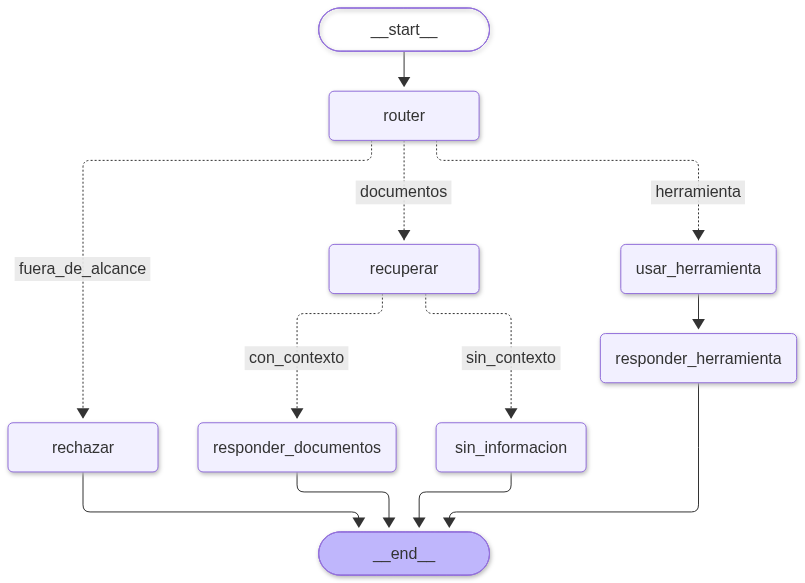

In [6]:
display(Image(filename=RESULTADOS / "grafo.png", width=520))

In [7]:
from eciguia.graph import EciGuiaAgent

mostrar_codigo(EciGuiaAgent._build)

```python
    def _build(self):
        g = StateGraph(AgentState)
        g.add_node("router", self.route)
        g.add_node("recuperar", self.retrieve)
        g.add_node("responder_documentos", self.answer_from_docs)
        g.add_node("sin_informacion", self.no_info)
        g.add_node("usar_herramienta", self.use_tool)
        g.add_node("responder_herramienta", self.answer_from_tool)
        g.add_node("rechazar", self.reject)

        g.add_edge(START, "router")
        g.add_conditional_edges("router", lambda s: s["route"], {
            "documentos": "recuperar",
            "herramienta": "usar_herramienta",
            "fuera_de_alcance": "rechazar",
        })
        g.add_conditional_edges("recuperar", lambda s: "con_contexto" if s["hits"] else "sin_contexto", {
            "con_contexto": "responder_documentos",
            "sin_contexto": "sin_informacion",
        })
        g.add_edge("usar_herramienta", "responder_herramienta")
        for node in ("responder_documentos", "sin_informacion", "responder_herramienta", "rechazar"):
            g.add_edge(node, END)
        return g.compile()
```

### 3.5 Herramientas por MCP

Las herramientas viven en un **servidor MCP** (Model Context Protocol) hecho con FastMCP. El agente lo lanza como subproceso y habla con él por stdio, como haría cualquier cliente MCP (Claude Desktop, por ejemplo), y mantiene la conexión abierta durante la sesión. El agente no conoce las funciones de antemano: lista las herramientas del servidor y le pasa al LLM su nombre, su descripción y su esquema de argumentos para que elija.

- `consultar_calendario(consulta, periodo?)`: busca eventos del calendario 2027 por palabras clave y devuelve fechas, estado (ya pasó, en curso o próximo) y días que faltan.
- `dias_hasta(fecha)`: días calendario hasta una fecha.
- `calcular_promedio_ponderado(asignaturas)`: promedio ponderado por créditos, como el promedio acumulado del Reglamento Estudiantil (art. 80).

La celda siguiente usa el servidor MCP real, en memoria y sin LLM, así que corre también sin Ollama.

In [8]:
from fastmcp import Client
from eciguia.mcp_server import mcp

async with Client(mcp) as cliente:
    for herramienta in await cliente.list_tools():
        print(f"· {herramienta.name}: {herramienta.description.splitlines()[0]}")
    fechas = await cliente.call_tool("consultar_calendario", {"consulta": "cancelación de semestre"})
    promedio = await cliente.call_tool("calcular_promedio_ponderado",
                                       {"asignaturas": [{"nota": 4.2, "creditos": 3}, {"nota": 3.6, "creditos": 4}]})

print("\nconsultar_calendario('cancelación de semestre'):")
display(pd.DataFrame(fechas.data))
print("calcular_promedio_ponderado:", promedio.data)

· consultar_calendario: Busca fechas en el calendario académico 2027 de la Escuela (preinscripción, pagos de matrícula,
· dias_hasta: Calcula cuántos días faltan desde hoy hasta una fecha en formato AAAA-MM-DD.
· calcular_promedio_ponderado: Calcula el promedio ponderado por créditos de una lista de asignaturas, como el promedio
· consultar_valores_2027: Valores oficiales en pesos para 2027: el valor de la MATRÍCULA de pregrado (por programa y rango
· consultar_plan_estudios: Plan de estudios de INGENIERÍA DE SISTEMAS: asignaturas, códigos, semestre y créditos, y el total de

consultar_calendario('cancelación de semestre'):


,evento,periodo,inicio,fin,estado,dias_para_inicio
0,Fecha límite de cancelación de semestre,2027-1,15 de mayo de 2027,15 de mayo de 2027,próximo,172
1,Fecha límite de cancelación de semestre,2027-i,15 de julio de 2027,15 de julio de 2027,próximo,233
2,Fecha límite de cancelación de semestre,2027-2,20 de noviembre de 2027,20 de noviembre de 2027,próximo,361
3,Fecha límite de cancelación de semestre,2026-2,21 de noviembre de 2026,21 de noviembre de 2026,ya pasó,-3


calcular_promedio_ponderado: {'promedio_un_decimal': 3.9, 'promedio_exacto': 3.857, 'creditos': 7}


### 3.6 Prompts versionados

Los prompts están en `prompts.py` y cada versión tiene nombre propio, así se puede medir cada cambio: `ROUTER_V1` y `ROUTER_V2`, y `RAG_ANSWER_BASICO`, `RAG_ANSWER_V1`, `RAG_ANSWER_V2` y `RAG_ANSWER_V3`. La app usa `ROUTER_V2` y `RAG_ANSWER_V3`. Cada regla responde a un fallo concreto observado con el modelo real (sección 4.4).

In [9]:
print(prompts.RAG_ANSWER)

Eres EciGuía, asistente académico de la Universidad Escuela Colombiana de Ingeniería Julio Garavito.
Responde la pregunta del estudiante usando ÚNICAMENTE los fragmentos de reglamentos de abajo.

Reglas:
1. Si algún fragmento responde la pregunta, directa o indirectamente, da la respuesta y cita su número entre corchetes, por ejemplo [1] o [2]. Una respuesta indirecta cuenta: si preguntan por "medio tiempo" y un fragmento exige "tiempo completo", la respuesta es que no, y se cita ese fragmento.
2. Solo si la pregunta se responde con sí o no ("¿puedo...?", "¿hay...?", "¿se permite...?"), empieza con "Sí" si el reglamento permite o confirma lo que el estudiante pregunta, o con "No" si lo prohíbe o lo niega. Ejemplo: "¿Puedo desistir de algo obligatorio?" -> "No, ...". En las demás preguntas no empieces con "Sí" ni con "No".
3. Solo si NINGÚN fragmento trata el tema de la pregunta, escribe únicamente esta frase y nada más: "No encontré esa información en los reglamentos que tengo."
4. No 

### 3.7 Demostración

Cuatro preguntas, una por cada ruta, más una trampa cuya respuesta no está en los documentos cargados.

In [10]:
PREGUNTAS_DEMO = [
    "¿Qué porcentaje de créditos necesito para hacer la práctica?",
    "¿Hasta cuándo puedo cancelar el semestre?",
    "Saqué 4.2 en una materia de 3 créditos y 3.6 en una de 4, ¿cuál es mi promedio?",
    "¿Cuántas faltas de asistencia se permiten antes de perder una materia?",
    "¿Me recomiendas una película?",
    "¿Cuánto cuesta la matrícula de ingeniería en 2027?",
    "¿En qué semestre se ve Arquitecturas de Software?",
    "¿Qué requisitos hay para hacer doble programa?",
]

if EN_VIVO:
    # En la app el servidor MCP corre como subproceso (stdio). El kernel de Jupyter en Windows usa un event loop
    # que no puede lanzar subprocesos, así que aquí el agente se conecta al MISMO servidor MCP en memoria.
    agente = EciGuiaAgent(mcp_target=mcp)
    demo = []
    for p in PREGUNTAS_DEMO:
        s = await agente.ask(p)
        assert not s.get("error"), s["error"]
        demo.append({"pregunta": p, "ruta": s["route"], "herramienta": s.get("tool_name", ""),
                     "respuesta": s["answer"], "fuentes": s.get("sources", []), "latencia_s": s["latency_s"]})
    (RESULTADOS / "demo.json").write_text(json.dumps(demo, indent=2, ensure_ascii=False), encoding="utf-8")
else:
    demo = json.loads((RESULTADOS / "demo.json").read_text(encoding="utf-8"))

for d in demo:
    fuentes = "".join(f"\n  - {f}" for f in d["fuentes"]) or " ninguna"
    herramienta = f" · herramienta `{d['herramienta']}`" if d["herramienta"] else ""
    display(Markdown(f"**❓ {d['pregunta']}**\n\n{d['respuesta']}\n\n"
                     f"*Ruta: `{d['ruta']}`{herramienta} · {d['latencia_s']} s · fuentes:*{fuentes}\n\n---"))

**❓ ¿Qué porcentaje de créditos necesito para hacer la práctica?**

Para acceder al programa de prácticas profesionales, necesitas haber cursado y aprobado el setenta y cinco por ciento (75 %) de los créditos académicos de tu plan de estudios [4].

*Ruta: `documentos` · 15.8 s · fuentes:*
  - [1] Reglamento de Prácticas Profesionales en Pregrado, Artículo 19. Asignaturas adicionales durante la práctica profesional (pág. 13)
  - [2] Lineamientos para Práctica Docente (2023) (pág. 4)
  - [3] Reglamento de Prácticas Profesionales en Pregrado, Artículo 26. Pago de derechos de matrícula para prácticas profesionales (pág. 18)
  - [4] Reglamento de Prácticas Profesionales en Pregrado, Artículo 10. Requisitos para solicitar el acceso al programa de prácticas profesionales (pág. 9)

---

**❓ ¿Hasta cuándo puedo cancelar el semestre?**

Puedes cancelar el semestre hasta el 20 de noviembre de 2027, que corresponde al periodo 2027-2. Este es el evento más próximo cuyo estado no sea "ya pasó".

*Ruta: `herramienta` · herramienta `consultar_calendario` · 13.3 s · fuentes:*
  - Calendario Académico 2027

---

**❓ Saqué 4.2 en una materia de 3 créditos y 3.6 en una de 4, ¿cuál es mi promedio?**

Tu promedio ponderado sería 3.86 (3.857), considerando los créditos de las materias que mencionaste.

*Ruta: `herramienta` · herramienta `calcular_promedio_ponderado` · 13.84 s · fuentes:*
  - Herramienta MCP: calcular_promedio_ponderado

---

**❓ ¿Cuántas faltas de asistencia se permiten antes de perder una materia?**

No encontré esa información en los reglamentos que tengo.

*Ruta: `documentos` · 8.79 s · fuentes:* ninguna

---

**❓ ¿Me recomiendas una película?**

Solo puedo ayudarte con temas académicos de la Escuela: reglamentos de prácticas, opción de grado, trabajos dirigidos, movilidad, inglés, doble programa, créditos adicionales, cancelación de asignaturas, líneas de énfasis, el calendario académico 2027, los valores de matrícula y derechos pecuniarios 2027, el plan de estudios de Ingeniería de Sistemas y cálculo de promedios. Para otros temas te recomiendo consultar otra fuente.

*Ruta: `fuera_de_alcance` · 2.98 s · fuentes:* ninguna

---

**❓ ¿Cuánto cuesta la matrícula de ingeniería en 2027?**

La matrícula para el año 2027 en los programas de Ingeniería (sin incluir Ingeniería Biomédica) variará según el rango socioeconómico del estudiante, con valores mínimos de $7.961.000 y máximos de $16.782.500.

*Ruta: `herramienta` · herramienta `consultar_valores_2027` · 16.49 s · fuentes:*
  - Resolución de Rectoría N.° 014 de 2026 (18 de agosto de 2026), Derechos de Matrícula 2027 para los Programas de Pregrado (herramienta MCP consultar_valores_2027)

---

**❓ ¿En qué semestre se ve Arquitecturas de Software?**

En el plan de estudios desde 2025-1, Arquitecturas de Software se imparte en el semestre 6. Para estudiantes que ingresaron antes de ese periodo, esta asignatura se encuentra en el semestre 8.

*Ruta: `herramienta` · herramienta `consultar_plan_estudios` · 13.96 s · fuentes:*
  - Planes de estudio oficiales de Ingeniería de Sistemas (mallas en PDF de la Escuela) (herramienta MCP consultar_plan_estudios)

---

**❓ ¿Qué requisitos hay para hacer doble programa?**

Para hacer doble programa, el estudiante debe:

- Tener tres matrículas completas en semestres lectivos regulares [1].
- Acreditar un promedio acumulado de 3,50 o superior [1].
- No encontrarse en situación de alto riesgo académico [1].
- No tener amonestaciones ni sanciones disciplinarias vigentes [1, 3].
- Presentar las pruebas Saber Pro correspondientes a cada programa [2].

Estos requisitos deben ser cumplidos antes de formalizar la intención de cursar el doble programa.

*Ruta: `documentos` · 19.88 s · fuentes:*
  - [1] Condiciones de la Intención de Doble Programa (Consejo Académico, Acta 382 de 2026) (pág. 2)
  - [2] Condiciones de la Intención de Doble Programa (Consejo Académico, Acta 382 de 2026) (pág. 3)
  - [3] Condiciones de la Intención de Doble Programa (Consejo Académico, Acta 382 de 2026) (pág. 2)
  - [4] Condiciones de la Intención de Doble Programa (Consejo Académico, Acta 382 de 2026) (pág. 2)

---

### 3.8 Segunda etapa: ampliación del corpus

Después de la primera evaluación se agregaron 12 PDF oficiales nuevos. El objetivo era **ampliar lo que sabe el asistente sin empeorar lo que ya funcionaba**. Los PDF no eran homogéneos, así que cada tipo de fuente recibió un tratamiento distinto:

| Tipo de fuente | Documentos | Tratamiento |
| --- | --- | --- |
| Prosa normativa con texto | Reglamento de líneas de énfasis, lineamientos de práctica docente (2023), condiciones del doble programa (Acta 382 de 2026) | RAG, igual que los anteriores |
| **PDF escaneados** (sin texto) | Créditos adicionales (Acuerdo 01 de 2017), cancelación de asignaturas (Acuerdos 02 de 2017 y 001 de 2025), régimen de participación estudiantil (Acuerdos 70 y 71 de 2017) | Transcritos a mano a `data/transcripciones/*.md`, con marcadores de página para citar la página original, y **verificados por el autor contra el PDF** |
| **Tablas** | Matrícula 2027 (Res. 014 de 2026), derechos pecuniarios 2027 (Res. 016 de 2026), planes de estudio de Ingeniería de Sistemas (antes y desde 2025-1) | Transcritas a JSON y consultadas con **dos herramientas MCP nuevas**: `consultar_valores_2027` y `consultar_plan_estudios`. pdfplumber extraía las mallas como texto revuelto ("P y r E o s b t a a b d i í l s id ti a c d a"), inservible para RAG. Las sumas de créditos por semestre y por núcleo se verificaron con código contra los totales oficiales (139 y 158) |
| **Descartados** | Reglamento Estudiantil de 2018 y una copia duplicada de la modificación 2025 | Fuera del corpus. El reglamento de 2018 trae la versión **derogada** de los artículos 46, 69, 70, 80 y 84; indexarlo junto con la modificación de 2025 habría permitido citar normas que ya no rigen |

**Salvaguardas para no dañar lo anterior:**
- Antes de tocar la ingesta se guardó una copia de los fragmentos de los 6 documentos originales. Después de cada cambio se comprobó que siguieran **idénticos** (128 por artículo y 138 de tamaño fijo).
- Las 40 preguntas originales se conservaron sin cambios como **prueba de regresión**. Las preguntas nuevas van en un set aparte (`eval/golden_set_ampliacion.jsonl`, 26 preguntas: 14 de documentos, 8 de herramientas, 3 trampas y 1 fuera de alcance).
- `eval/regresion.py` compara dos corridas pregunta por pregunta y lista lo que empeora y lo que mejora.
- La página 1 del acta de doble programa (la lista de asistentes, con nombres propios) se excluye del índice.

El índice pasó de 6 a **13 documentos** y de 128 a **208 fragmentos**. El router pasó a `ROUTER_V3`, con los temas nuevos y una regla explícita para la palabra "matrícula", que ahora tiene cuatro destinos: cuánto cuesta en pesos (herramienta de valores), qué porcentaje se paga en una práctica o un intercambio (reglamentos), cuándo se paga (calendario) y otra universidad (fuera de alcance).

In [11]:
from eciguia.tools_logic import consultar_plan_estudios

mostrar_codigo(consultar_plan_estudios)

async with Client(mcp) as cliente:
    matricula = await cliente.call_tool("consultar_valores_2027", {"consulta": "matrícula", "programa": "ingeniería de sistemas"})
    grado = await cliente.call_tool("consultar_valores_2027", {"consulta": "gastos de grado"})
    arsw = await cliente.call_tool("consultar_plan_estudios", {"consulta": "Arquitecturas de Software"})
    civil = await cliente.call_tool("consultar_plan_estudios", {"consulta": "quinto semestre de Ingeniería Civil"})

print("Matrícula 2027, ingenierías:", matricula.data["valores"])
print("Gastos de grado:", grado.data["resultados"][0]["valor_2027"])
print("Arquitecturas de Software:", [(p["plan"].split(" (")[0], p["asignaturas"][0]["semestre"]) for p in arsw.data["planes"]])
print("Trampa (otro programa):", civil.data["aviso"])

```python
def consultar_plan_estudios(consulta: str, plan: str | None = None) -> dict:
    """Asignaturas, semestre y créditos de los planes de estudio de Ingeniería de Sistemas
    (desde 2025-1 y antes de 2025-1). No incluye prerrequisitos ni otros programas."""
    datos = load_study_plans()
    texto = _normalize(consulta)
    otro = _otro_programa(texto)
    if otro and "sistemas" not in texto:
        # Solo existe el plan de Sistemas: responder con él una pregunta sobre otro programa sería un error
        return {"fuente": "Planes de estudio oficiales de Ingeniería de Sistemas", "planes": [],
                "aviso": f"Solo tengo el plan de estudios de Ingeniería de Sistemas. No tengo el plan de {otro}."}
    claves = [plan] if plan in datos["planes"] else _plan_pedido(texto)
    semestre = _semestre_pedido(texto)
    codigos = {w.upper() for w in re.findall(r"[a-z0-9]{4,6}", texto)}
    palabras = [w for w in re.findall(r"[a-z0-9]+", texto) if w not in STOPWORDS_PLAN and len(w) > 2]
    salida = []
    for clave in claves:
        p = datos["planes"][clave]
        asignaturas = p["asignaturas"]
        if por_codigo := [a for a in asignaturas if a["codigo"] in codigos]:
            elegidas = por_codigo
        elif semestre is not None:
            elegidas = [a for a in asignaturas if a["semestre"] == semestre]
        else:
            puntajes = [(sum(1 for w in palabras if w[:5] in _normalize(a["nombre"])), a) for a in asignaturas]
            mejor = max((s for s, _ in puntajes), default=0)
            elegidas = [a for s, a in puntajes if mejor and s == mejor]
        salida.append({
            "plan": p["nombre"],
            "resumen": {"total_creditos": p["total_creditos"], "semestres": p["semestres"],
                        "creditos_por_semestre": p["creditos_por_semestre"], "creditos_por_nucleo": p["creditos_por_nucleo"],
                        "nota": p["nota_total"]},
            "asignaturas": [{"codigo": a["codigo"], "nombre": a["nombre"], "creditos": a["creditos"],
                             "semestre": a["semestre"]} for a in elegidas[:15]],
        })
    return {
        "fuente": "Planes de estudio oficiales de Ingeniería de Sistemas (mallas en PDF de la Escuela)",
        "planes": salida,
        "limitaciones": "Solo Ingeniería de Sistemas. No incluye prerrequisitos.",
    }
```

Matrícula 2027, ingenierías: [{'rango': 1, 'pagina': 1, 'Ingenierías (no incluye Ingeniería Biomédica)': '$7.961.000'}, {'rango': 12, 'pagina': 2, 'Ingenierías (no incluye Ingeniería Biomédica)': '$16.782.500'}]
Gastos de grado: $979.000
Arquitecturas de Software: [('Plan de estudios N.° 15 de Ingeniería de Sistemas', 6), ('Plan de estudios de Ingeniería de Sistemas', 8)]
Trampa (otro programa): Solo tengo el plan de estudios de Ingeniería de Sistemas. No tengo el plan de Ingeniería Civil.


## 4. Resultados y discusión

### 4.1 Diseño de la evaluación

**Set de evaluación** (`eval/golden_set.jsonl`): 40 preguntas con respuesta conocida, transcrita de los documentos oficiales:
- 25 de **reglamentos**, cada una con el documento y el artículo donde está la respuesta.
- 8 de **herramientas**: 6 fechas del calendario y 2 promedios.
- 5 **fuera de alcance** (películas, otra universidad, programación, datos personales, fútbol).
- 2 **trampas**: preguntas que suenan a la Escuela pero cuya respuesta no está en los documentos cargados (horario de la cafetería y faltas de asistencia).

**Métricas:**

| Métrica | Qué mide | Sobre qué preguntas |
| --- | --- | --- |
| Recuperación (hit@4) | ¿El fragmento con la respuesta está entre los 4 recuperados? Criterio por páginas, igual para las dos estrategias | 25 de reglamentos |
| Ruteo correcto | ¿El router eligió la ruta esperada? | 40 |
| Herramienta correcta | ¿Usó la herramienta MCP esperada? | 8 de herramientas |
| Rechazo correcto | ¿Rechazó o dijo "no encontré" en vez de inventar? | 7 fuera de alcance y trampas |
| Acierto (juez) | ¿La respuesta contiene la información clave sin contradecirla? | 33 con respuesta |
| Fidelidad (juez) | ¿Todo lo que afirma está respaldado por el contexto que recibió? | 33 con respuesta |

El acierto y la fidelidad los califica un **LLM como juez** (el mismo Qwen 2.5 7B en modo JSON), validado a mano en la sección 4.3.

**Experimentos.** Cada corrida cambia **una sola cosa** respecto a la anterior, para poder atribuirle la diferencia:

| Corrida | Qué cambia |
| --- | --- |
| `1_base` | Línea base: sin router (todo va a RAG), prompt básico, chunking de tamaño fijo |
| `2_chunk_articulo` | Chunking por artículo |
| `3_router_tools` | Router + herramientas MCP |
| `4_prompt_v1` | Prompt RAG con reglas (V1) |
| `5_prompt_v2` | Prompt RAG V2 (corrige respuestas que pegaban "no encontré" al final) |
| `6_final` | Router V2 + prompt RAG V3 (corrigen los fallos de la sección 4.4). Es la configuración de la app |

Todas usan el umbral calibrado de 0,45, `top_k = 4` y temperatura 0. La evaluación completa tarda alrededor de 12 minutos por corrida en una RTX 3050 de 6 GB, así que aquí se cargan los resúmenes guardados. Se reproducen con los comandos del README.

In [12]:
# Resumen de las 6 corridas (docs/resultados/<corrida>.json), con el acierto separado por tipo de pregunta
tabla = pd.read_csv(RESULTADOS / "comparativa.csv").set_index("corrida").fillna({"router": "—"})
porcentajes = [c for c in tabla.columns if c not in ("chunking", "router", "prompt RAG", "Latencia mediana (s)")]
tabla.style.format({c: "{:.0%}" for c in porcentajes}).format({"Latencia mediana (s)": "{:.1f}"})

,chunking,router,prompt RAG,Recuperación hit@4,Ruteo,Herramienta,Rechazo,Acierto (juez),Fidelidad (juez),Acierto reglamentos,Acierto fechas/cálculos,Latencia mediana (s)
corrida,,,,,,,,,,,,
1_base,fijo,—,basico,0.960000,0.675000,0.000000,0.857000,0.818000,0.758000,1.000000,0.250000,13.8
2_chunk_articulo,articulo,—,basico,1.000000,0.675000,0.000000,1.000000,0.758000,0.758000,0.960000,0.125000,12.2
3_router_tools,articulo,v1,basico,1.000000,0.925000,1.000000,1.000000,0.879000,0.939000,0.840000,1.000000,14.1
4_prompt_v1,articulo,v1,v1,1.000000,0.925000,1.000000,1.000000,0.848000,0.909000,0.800000,1.000000,12.1
5_prompt_v2,articulo,v1,v2,1.000000,0.925000,1.000000,1.000000,0.879000,0.939000,0.840000,1.000000,12.5
6_final,articulo,v2,v3,1.000000,0.975000,1.000000,1.000000,0.939000,0.939000,0.920000,1.000000,12.2


**Qué muestra la tabla.**

1. **Chunking: el chunking por artículo recupera mejor y permite citar el artículo.** La recuperación pasa de 96 % (tamaño fijo) a 100 % (por artículo). El único fallo del chunking fijo es d07 ("¿Puedo inscribir materias mientras hago la práctica?"): el artículo 19 de prácticas no entra en el top 4. Curiosamente, la respuesta salió bien igual, porque recuperó un parágrafo del reglamento de movilidad que repite la regla de los 6 créditos. Además, la recuperación por artículo se mide con un criterio por páginas, que es laxo: en la misma página puede haber otro artículo, y eso favorece al chunking fijo. Con el criterio exacto (el artículo esperado entre los 4 fragmentos), el chunking por artículo también llega al 100 %. Lo más valioso, sin embargo, es cualitativo: cada fragmento es una unidad normativa completa y la cita dice "Artículo 26. Pago de derechos de matrícula… (pág. 18)", no solo una página. El 96 % frente al 100 % equivale a una pregunta de 25, así que con este corpus pequeño la diferencia de recuperación es modesta.

2. **El RAG básico ya responde bien los reglamentos; lo que aporta el agente está en el resto.** Sin router, todas las preguntas de reglamentos llegan al RAG y el acierto en ellas es del 96 % al 100 %: con 6 documentos y fragmentos bien hechos, la recuperación casi no falla. El salto del agente (corrida 3) está en lo que el RAG no puede hacer:
   - Las fechas del calendario y los promedios pasan de **12 % a 25 %** a **100 %**: el calendario no está en los PDF y el LLM calcula mal.
   - La herramienta correcta se elige en el **100 %** de los casos.
   - El rechazo correcto llega al **100 %**, y las preguntas fuera de alcance se rechazan en unos 3 segundos sin buscar ni generar. En la línea base ya era alto (86 %) gracias al umbral calibrado: casi todas se quedaban sin fragmentos y terminaban en "no encontré". Su único "fallo" (f07) en realidad no inventó nada; respondió "no se menciona ninguna información sobre las faltas de asistencia", pero no usó la frase que la métrica detecta. Es una limitación de medir los rechazos por texto exacto.

   La fidelidad sube de 76 % a 94 %. Sin calendario, la línea base respondía las preguntas de fechas con "no encontré" o con fragmentos irrelevantes de los reglamentos (a "¿Hasta cuándo puedo cancelar asignaturas?" respondió hablando de asignaturas reprobadas). Los dos promedios los calculó bien el propio LLM, pero sin ningún respaldo, y por eso el juez los marcó como no fieles.

3. **El router tiene un costo.** Al agregarlo, el acierto en reglamentos **baja** de 96 % a 84 %: el router V1 desvía 3 preguntas de costos de matrícula (fallo 1, sección 4.4). Es el precio de dividir el problema: cada decisión intermedia es un punto nuevo de fallo. Con el router V2 el ruteo llega al **98 %** (39 de 40) y el acierto en reglamentos al **92 %**. El router V2 corrige esas 3 preguntas pero introduce una regresión: "¿Quiénes forman el jurado de la sustentación del trabajo dirigido?" ahora se rechaza como fuera de alcance, probablemente por la regla de "datos personales de alguien". Preferí reportarla en vez de seguir ajustando el prompt sobre el mismo set de evaluación, porque eso sería sobreajustar.

4. **Los prompts con reglas no mejoraron solos el acierto; sí la forma de las respuestas.** La V1 bajó el acierto en reglamentos de 84 % a 80 %: empezó a decir "no encontré" en preguntas que sí tenían respuesta (fallo 2). La V2 corrigió que pegara "no encontré" al final de respuestas buenas. La V3 resolvió la inferencia indirecta y la polaridad de los sí/no (fallos 2 y 3). La diferencia entre versiones es de 1 o 2 preguntas sobre 25, del mismo orden que el error del juez (sección 4.3), así que **las cifras de una corrida a otra no son concluyentes por sí solas**. Por eso cada cambio se justifica también con los casos concretos que corrige.

5. **Revisión humana de la corrida final.** Como el juez es permisivo (sección 4.3), se revisaron a mano las 33 respuestas de `6_final`. **El contenido es correcto en 32 de 33**: la única incorrecta es d18, por la regresión del router. Dos diferencias con el juez: d06 la marcó como incorrecta y está bien (es la misma respuesta correcta que ya había penalizado en la corrida 3), y en t08 la respuesta agrega una frase sin respaldo ("en el periodo más reciente"), aunque el promedio es correcto. También se verificaron los días que faltan en las respuestas de fechas (59, 178, 45 y 200), y todos son correctos. Queda un detalle de estilo: en 5 respuestas (d02, d05, d14, d20, d25) el modelo empieza con "Sí" aunque la pregunta no es de sí o no ("Sí, un trabajo dirigido tiene… tres créditos"). No cambia el contenido, pero es un tic del modelo de 7B que el recordatorio del prompt V3 corrigió en las preguntas que sí son de sí o no, sin eliminarlo del todo. Además, el sistema rechaza correctamente las **7 de 7** preguntas fuera de alcance o trampa.

6. **Latencia.** La mediana es de unos 12 segundos por pregunta en una RTX 3050 de 6 GB: alrededor de 3 s en rechazos, 12 s en reglamentos y 16 s con herramientas, que requieren tres llamadas al LLM (router, selección de herramienta y redacción). Es aceptable para consultas académicas, pero es la principal limitación de experiencia de usuario de correr todo local.

### 4.2 Calibración del umbral de relevancia

El umbral decide si hay evidencia suficiente para responder. Para elegirlo con datos (`eval/calibrate.py`) se midió la distancia coseno del mejor fragmento para 25 preguntas cuya respuesta sí está en los documentos (positivas) y 27 cuya respuesta no está (negativas): las 7 fuera de alcance y trampas del set, más 20 preguntas nuevas que suenan a la Escuela, como horario de la biblioteca, nota mínima o carné (`eval/calibracion_negativas.jsonl`).

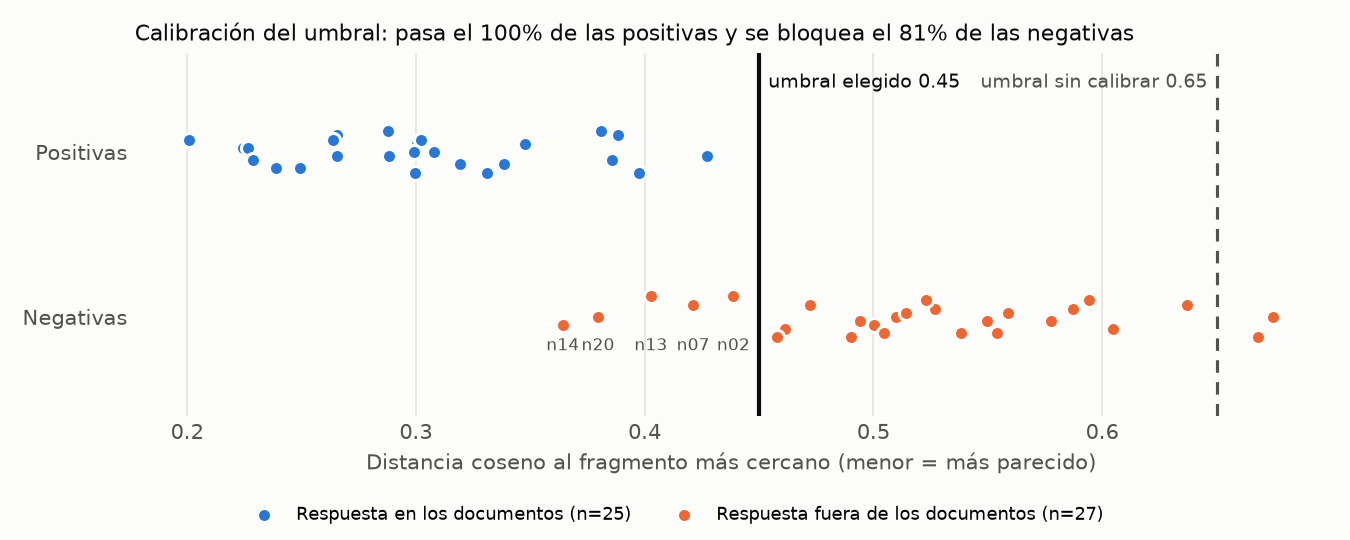

,positivas_que_pasan,negativas_bloqueadas
umbral,,
0.350000,80%,100%
0.400000,96%,93%
0.450000,100%,82%
0.500000,100%,63%
0.550000,100%,33%
0.600000,100%,15%
0.650000,100%,7%


In [13]:
display(Image(filename=RESULTADOS / "calibracion_etapa1.png", width=820))
calibracion = json.loads((RESULTADOS / "calibracion_etapa1.json").read_text(encoding="utf-8"))
curva = pd.DataFrame(calibracion["curva"]).set_index("umbral")
curva.loc[[0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]].style.format("{:.0%}")

- **El valor inicial (0,65) casi no filtraba:** dejaba pasar el 93 % de las negativas. Con `bge-m3`, incluso una pregunta sobre fútbol queda a una distancia de 0,68 de algún reglamento.
- **Criterio elegido:** el umbral más estricto que conserva **todas** las positivas, más un margen de 0,02 para preguntas redactadas distinto, lo que da **0,45**. Con él pasa el 100 % de las positivas y se bloquea el **81 %** de las negativas, incluidas las dos trampas del set.
- **Por qué no 0,40**, que bloquea el 93 % de las negativas: deja por fuera una pregunta válida (d02, a 0,427). Los dos errores no cuestan lo mismo. Una positiva bloqueada termina en "no encontré" sin segunda oportunidad, mientras que una negativa que se cuela todavía pasa por el prompt RAG, que tiene la regla de no responder sin evidencia. Así ocurrió con "¿Cuántas faltas de asistencia se permiten…?" en las pruebas iniciales, cuando se coló con el umbral de 0,65 y el modelo respondió "no encontré".
- **Las 5 negativas que pasan el umbral** (pago con tarjeta de crédito, periodo de prueba académica, certificado de notas, créditos de ingeniería civil, nota mínima) son las más difíciles: están en el dominio y comparten vocabulario con los reglamentos. Para ellas, la defensa es el prompt.
- Con 52 preguntas la calibración es indicativa, no definitiva. Al agregar documentos habría que recalibrar.

### 4.3 Validación del juez

Un juez automático sin validar no es creíble, así que se revisaron a mano 10 veredictos de la corrida `5_prompt_v2`: los 4 que el juez marcó como incorrectos y 6 correctos elegidos al azar (semilla fija).

In [14]:
juez = pd.read_csv(RESULTADOS / "validacion_juez.csv")
coinciden = (juez["juez_correcta"] == juez["revision_manual"]).sum()
print(f"El juez coincide con la revisión manual en {coinciden} de {len(juez)} casos")
juez

El juez coincide con la revisión manual en 8 de 10 casos


,id,pregunta,respuesta,juez_correcta,revision_manual,comentario_juez,nota
0,d04,¿Cuál es la duración máxima de una práctica internacional?,"La práctica profesional internacional tendrá una duración máxima de un (1) año, según el Artículo 13 del Reglamento ...",True,True,Información precisa y concisa.,"Da el máximo (1 año), que es lo que pregunta; omite el mínimo, que no se pidió."
1,d08,¿Cuánto de la matrícula tengo que pagar durante la práctica profesional?,"El evento más próximo es el ""Pago de matrícula extraordinario"" para el periodo 2027-1, que comienza el 18 de diciemb...",False,False,No menciona el porcentaje.,"Error del router: respondió con fechas de pago, no con el porcentaje."
2,d09,¿Hay algún descuento en la matrícula si hago la práctica en el exterior?,"Solo puedo ayudarte con temas académicos de la Escuela: reglamentos de prácticas, opción de grado, trabajos dirigido...",False,False,Respuesta irrelevantes al tema.,Error del router: rechazó una pregunta que sí está en el reglamento.
3,d10,¿La práctica profesional puede ser de medio tiempo?,No encontré esa información en los reglamentos que tengo.,False,False,Respuesta incorrecta sobre dedicación.,"El artículo 14 se recuperó, pero el modelo no dedujo 'tiempo completo, luego no medio tiempo'."
4,d12,"Si ya acepté una oferta de práctica, ¿puedo echarme para atrás?","Sí, según el Parágrafo 1 del Artículo 11 del Reglamento de Prácticas Profesionales en Pregrado [1], la aceptación de...",True,False,Coincide con la respuesta esperada.,Empieza con 'Sí' y luego dice que no puede desistir: contradictoria. El juez fue permisivo.
5,d19,¿Hasta cuándo tengo para entregar el resultado final del trabajo dirigido?,"Según el Reglamento de Trabajos Dirigidos, Artículo 18 [1], debes entregar el resultado final del trabajo dirigido h...",True,True,Incluye la fecha límite y el aval del director.,Da la fecha límite; omite el aval del director (el comentario del juez dice lo contrario).
6,d22,¿Qué tan viejo puede ser mi certificado de IELTS para el requisito de inglés?,Tu certificado de IELTS debe tener una vigencia máxima de dos años en el momento de presentarlo al Departamento de H...,True,True,Información precisa y relevante.,Correcta y citada.
7,d24,¿Cuánto de la matrícula pago en la Escuela si me voy de intercambio internacional?,"Solo puedo ayudarte con temas académicos de la Escuela: reglamentos de prácticas, opción de grado, trabajos dirigido...",False,False,Respuesta incorrecta e incoherente.,Error del router: rechazó una pregunta de movilidad.
8,t01,¿Hasta cuándo puedo cancelar asignaturas en 2027-1?,"Según la información proporcionada, la fecha límite para cancelar asignaturas en el periodo 2027-1 es el 8 de mayo d...",True,True,Coincide con el contexto.,Fecha correcta.
9,t02,¿Cuál es la fecha límite para cancelar el semestre 2027-2?,La fecha límite para cancelar el semestre 2027-2 es el 20 de noviembre de 2027. Aunque esta fecha aún está a un año ...,True,False,Información precisa y concisa.,"Fecha correcta, pero afirma que 'solo queda un día' (faltan 365). El juez fue permisivo."


En los dos desacuerdos el juez fue **más permisivo** que la revisión humana: aceptó una respuesta que empieza con "Sí" para decir que algo no se puede (d12) y otra con la fecha correcta pero con una afirmación falsa sobre cuántos días faltan (t02). Además, en d19 el comentario del juez dice que la respuesta "incluye el aval del director" y no lo incluye. Conclusión: las cifras de acierto y fidelidad son un **techo**. Sirven para comparar versiones entre sí, porque el sesgo es el mismo en todas las corridas, pero no como medida absoluta. El juez también es el mismo modelo que responde (Qwen 2.5 7B); con una GPU de 6 GB no fue viable usar un juez más grande, y por eso se validó a mano.

### 4.4 Tres fallos analizados

**Fallo 1: el router confundía las preguntas de costos de matrícula (error de ruteo, sesgo del prompt).**
Con `ROUTER_V1`, 3 de las 25 preguntas de reglamentos se desviaron: "¿Cuánto de la matrícula tengo que pagar durante la práctica?" se fue a la **herramienta** de calendario (respondió con la fecha del pago extraordinario), y "¿Hay algún descuento en la matrícula si hago la práctica en el exterior?" y "¿Cuánto pago si me voy de intercambio?" se **rechazaron** como fuera de alcance. La causa estaba en el propio prompt: el único ejemplo con la palabra "matrícula" era "¿Cuánto cuesta la matrícula en la Universidad de los Andes? → fuera_de_alcance", y un modelo de 7B generaliza ese patrón superficial. `ROUTER_V2` separa explícitamente **cuánto se paga** (reglamentos), **cuándo se paga** (calendario) y **otra universidad** (fuera de alcance), con ejemplos que no son preguntas del set de evaluación. Como V2 se escribió mirando estos fallos, se comprobó en un **set aparte de 20 preguntas de ruteo** (`eval/ruteo_holdout.jsonl`): V1 y V2 aciertan las 20, es decir, la corrección no empeora el ruteo fuera del set de evaluación. Hay que reconocer que ese set no discrimina entre las dos versiones (V1 ya ruteaba bien otras redacciones con "matrícula"), así que la evidencia de que V2 **generaliza la mejora** es limitada.

**Fallo 2: "¿La práctica puede ser de medio tiempo?" respondía "no encontré" (inferencia indirecta y efecto secundario de una regla).**
El retriever sí traía el artículo 14 ("la práctica profesional tendrá una dedicación de tiempo completo"), pero con los prompts V1 y V2 el modelo respondía "No encontré esa información". Ningún fragmento dice literalmente "medio tiempo", y la regla "solo si ningún fragmento responde, di que no encontraste" se interpretó de forma literal. Es un efecto secundario de endurecer el prompt contra las alucinaciones: el prompt básico, sin reglas, sí acertaba esta pregunta. `RAG_ANSWER_V3` dice explícitamente que **una respuesta indirecta cuenta** y da el ejemplo de tiempo completo frente a medio tiempo. Es la tensión central de un asistente así: cada regla que reduce las alucinaciones aumenta las abstenciones innecesarias, y hay que medir las dos cosas.

**Fallo 3: polaridad de las respuestas sí/no y aritmética de fechas (limitaciones del modelo de 7B).**
Ante "Si ya acepté una oferta de práctica, ¿puedo echarme para atrás?", el modelo respondía "**Sí**, … genera un compromiso vinculante y no podrás desistir": el contenido es correcto, pero la primera palabra dice lo contrario, y es lo primero que lee el estudiante. Ni la regla general ni un ejemplo en las reglas lo corrigieron. Lo que funcionó fue **repetir la instrucción justo después de la pregunta**: los modelos pequeños obedecen mejor la última instrucción que leen. Un fallo parecido apareció con las fechas: hoy es 20 de noviembre de 2026, y ante "¿Cuál es la fecha límite para cancelar el semestre 2027-2?" (20 de noviembre de 2027) el modelo dijo que "solo queda un día", porque confundió el día y el mes con el año. La herramienta ya devolvía `dias_para_inicio = 365`. Se corrigió prohibiendo en el prompt que el modelo calcule días: debe copiar el número que calcula la herramienta. La lección es la misma que motivó usar herramientas: **cualquier cálculo, incluso trivial, debe hacerlo el código y no el LLM**.

### 4.5 Caso de estudio: 80 % frente a 75 % de los créditos

Los **Lineamientos de Opción de Grado** (de alrededor de 2020) piden haber aprobado el **80 %** de los créditos para la opción de grado. El **Reglamento de Prácticas Profesionales** (nueva versión de julio de 2026, art. 10) pide el **75 %** para acceder a la práctica, que es una de las opciones de grado. El prompt tiene una regla para mostrar ambas cifras cuando dos documentos se contradicen, pero el resultado depende de la recuperación:
- "¿Qué porcentaje de créditos necesito para hacer la práctica?" recupera 4 fragmentos del reglamento de prácticas y de movilidad. El asistente responde **75 %** con su cita, sin mencionar el 80 %.
- "¿Qué porcentaje de créditos necesito para la opción de grado?" recupera solo los lineamientos y responde **80 %**.
- En una corrida temprana, con otra segmentación, la primera pregunta sí trajo ambos documentos y el asistente mostró las dos cifras, cada una con su documento.

Cada respuesta es **fiel a lo que recuperó y está citada**, así que el estudiante puede ver de qué documento sale el dato. Pero el asistente no detecta la contradicción por sí mismo: la regla del prompt solo actúa si los dos fragmentos llegan juntos al contexto. Una mejora natural es diversificar la recuperación por documento (por ejemplo con MMR, o trayendo siempre el mejor fragmento de cada reglamento relacionado) o mantener una lista curada de normas que se cruzan. En la práctica, la recomendación para el estudiante es la que diría un consejero: ante dos cifras, consultar con la decanatura, y el asistente le da las dos referencias exactas para hacerlo.

### 4.6 Comprobación del router en un set aparte

Como `ROUTER_V2` se escribió mirando los fallos del set de evaluación, se midió también en 20 preguntas nuevas que no se usaron para escribir ningún prompt (`eval/compare_router.py`). Ambas versiones aciertan todas: la corrección no rompe el ruteo en preguntas nuevas, pero este set no alcanza a mostrar que la V2 sea mejor (fallo 1).

In [15]:
holdout = json.loads((RESULTADOS / "ruteo_holdout_etapa1.json").read_text(encoding="utf-8"))
print("Exactitud del router en el set aparte (etapa 1):", {v: f"{a:.0%}" for v, a in holdout["exactitud"].items()})
pd.DataFrame(holdout["preguntas"]).set_index("id")

Exactitud del router en el set aparte (etapa 1): {'v1': '100%', 'v2': '100%'}


,esperada,pregunta,v1,v2
id,,,,
h01,documentos,¿Cuánto pago de matrícula si hago una pasantía de investigación en el exterior?,documentos,documentos
h02,documentos,¿Me cobran la matrícula completa si estoy haciendo práctica social?,documentos,documentos
h03,documentos,¿Qué promedio necesito para aplicar a doble titulación?,documentos,documentos
h04,documentos,¿Quién califica el trabajo dirigido?,documentos,documentos
h05,documentos,¿Puedo homologar materias que vi en otra universidad?,documentos,documentos
h06,documentos,"Si me voy de intercambio a México, ¿qué tengo que pagar en la Escuela?",documentos,documentos
h07,documentos,¿El TOEFL sirve para el requisito de inglés?,documentos,documentos
h08,documentos,¿Cuántas materias puedo ver mientras estoy en práctica?,documentos,documentos
h09,herramienta,¿Hasta qué día tengo para pagar la matrícula sin recargo para 2027-2?,herramienta,herramienta


### 4.7 Segunda etapa: ¿se amplió el conocimiento sin dañar lo anterior?

La configuración final de la app (`ROUTER_V3` + `RAG_ANSWER_V3`, corpus de 13 documentos y 5 herramientas MCP) se evaluó con dos sets:
- **Set original (40 preguntas)** como prueba de regresión, comparado pregunta por pregunta con `6_final`.
- **Set de ampliación (26 preguntas)** sobre los documentos y herramientas nuevos: 14 de documentos, 8 de herramientas (valores 2027 y plan de estudios), 3 trampas (prerrequisitos que no están transcritos, matrícula de **maestría** y plan de **Ingeniería Civil**, para las que las herramientas tienen datos parecidos pero no los pedidos) y 1 fuera de alcance.

El umbral de relevancia se recalibró con el corpus ampliado (39 positivas y 31 negativas) y **no cambió**: con 0,45 siguen pasando todas las positivas y se bloquea el 77 % de las negativas (antes, el 81 %). Que la calibración se mantenga al agregar 7 documentos es evidencia de que no estaba sobreajustada al corpus inicial.

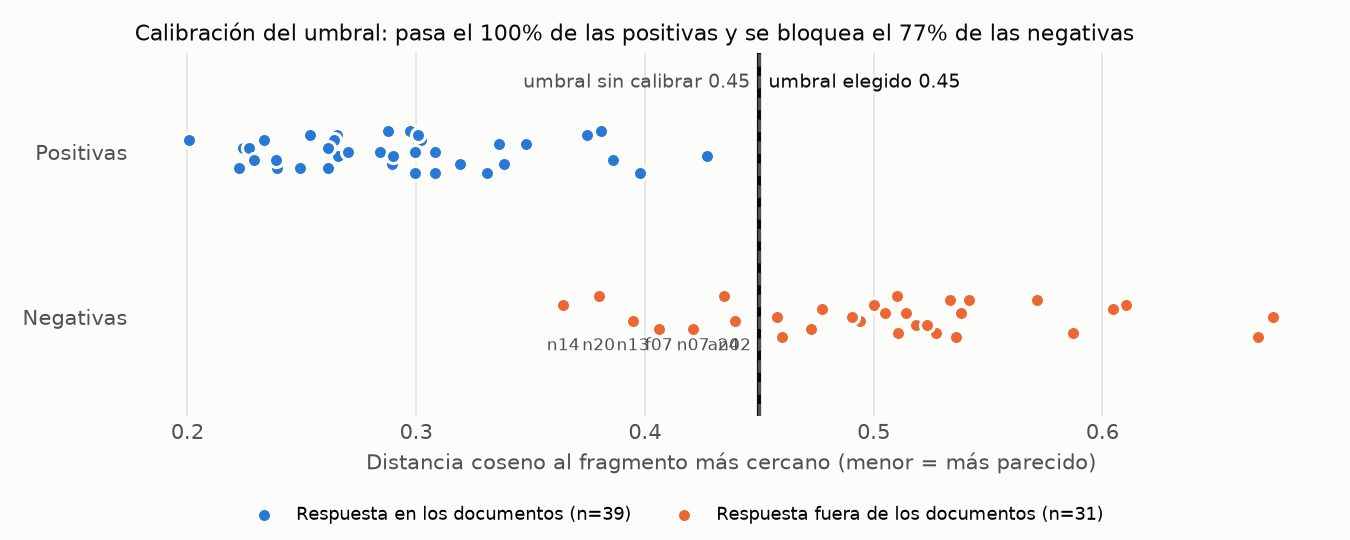

In [16]:
display(Image(filename=RESULTADOS / "calibracion.png", width=820))

In [17]:
# Segunda etapa: el set original (regresión) y el set de ampliación, con la configuración final de la app
filas = []
for corrida, nombre in [("6_final", "Etapa 1 · set original"), ("8_final_original", "Etapa 2 · set original"),
                        ("8_final_nuevas", "Etapa 2 · set de ampliación")]:
    r = json.loads((RESULTADOS / f"{corrida}.json").read_text(encoding="utf-8"))
    filas.append({"corrida": nombre, "n": r["n"], "Recuperación": r["hit@k_retriever"], "Ruteo": r["ruteo_correcto"],
                  "Herramienta": r["herramienta_correcta"], "Rechazo": r["rechazo_correcto"],
                  "Acierto (juez)": r["acierto_respuesta"], "Fidelidad (juez)": r["fidelidad"],
                  "Latencia mediana (s)": r["latencia_mediana_s"]})
etapa2 = pd.DataFrame(filas).set_index("corrida")
pct = [c for c in etapa2.columns if c not in ("n", "Latencia mediana (s)")]
etapa2.style.format({c: "{:.0%}" for c in pct}).format({"Latencia mediana (s)": "{:.1f}"})

,n,Recuperación,Ruteo,Herramienta,Rechazo,Acierto (juez),Fidelidad (juez),Latencia mediana (s)
corrida,,,,,,,,
Etapa 1 · set original,40,1.000000,0.975000,1.000000,1.000000,0.939000,0.939000,12.2
Etapa 2 · set original,40,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,12.5
Etapa 2 · set de ampliación,26,1.000000,1.000000,1.000000,1.000000,1.000000,0.955000,13.6


In [18]:
regresion = pd.read_csv(RESULTADOS / "regresion_6_final_vs_8_final_original.csv").fillna("")
print("Preguntas originales que empeoran:", (regresion["cambios"].str.contains("empeora")).sum(),
      "| que mejoran:", (regresion["cambios"].str.contains("mejora") & ~regresion["cambios"].str.contains("empeora")).sum())
regresion[regresion["cambios"] != ""][["id", "pregunta", "cambios", "ruta_antes", "ruta_despues"]]

Preguntas originales que empeoran: 0 | que mejoran: 2


,id,pregunta,cambios,ruta_antes,ruta_despues
5,d06,¿Puedo hacer la práctica docente en otra universidad?,mejora:correcta,documentos,documentos
17,d18,¿Quiénes forman el jurado de la sustentación del trabajo dirigido?,mejora:ruta_correcta mejora:correcta,fuera_de_alcance,documentos


In [19]:
holdout = json.loads((RESULTADOS / "ruteo_holdout.json").read_text(encoding="utf-8"))
print("Router en el set aparte (32 preguntas que no se usaron para escribir ningún prompt):",
      {v: f"{a:.0%}" for v, a in holdout["exactitud"].items()})

Router en el set aparte (32 preguntas que no se usaron para escribir ningún prompt): {'v1': '81%', 'v2': '84%', 'v3': '97%'}


**Resultados de la segunda etapa, con revisión humana de todas las respuestas:**
- **Set original: 0 regresiones.** Las 33 respuestas con contenido son correctas y las 7 trampas o fuera de alcance se rechazan bien. Además se corrigieron d18 (la regresión del router V2, gracias a la aclaración sobre roles en `ROUTER_V3`) y t07 (el comentario inventado sobre el promedio). La mejora de d06 en la tabla es solo el juez, que esta vez no se equivocó: la respuesta era correcta en las dos corridas.
- **Set de ampliación:** las 22 respuestas con contenido son correctas, con citas a los documentos nuevos (Acuerdo 01 de 2017, Acta 382 de 2026, Res. 014 y 016 de 2026, art. 7 y 16 del reglamento de énfasis, etc.). Las 4 trampas y la pregunta fuera de alcance se rechazan bien. La trampa de Ingeniería Civil se responde "no tengo el plan de estudios de Ingeniería Civil; solo dispongo del de Ingeniería de Sistemas", en vez de listar materias de Sistemas.
- **Router en el set aparte (32 preguntas nuevas, 12 de ellas sobre roles y temas de la segunda etapa):** V1 81 %, V2 84 %, **V3 97 %**. A diferencia de la etapa 1, este set sí distingue las versiones. El único fallo de V3 es "¿La Nacional tiene descuentos de matrícula por estrato?", que manda a documentos en vez de rechazar. No es grave: en documentos el umbral y el prompt terminan en "no encontré".
- La latencia mediana se mantuvo en unos 12 a 14 s.

**Fallos de la primera corrida de la segunda etapa y cómo se corrigieron.** La primera corrida sobre el set de ampliación (`7_ampliacion_nuevas`) mostró 4 tipos de fallo. Esta vez se corrigieron **en el código y no en el prompt**, porque la primera etapa ya mostró que el modelo de 7B no siempre obedece reglas de redacción:

1. **Herramienta sin argumento obligatorio** (3 preguntas). Ante "¿Cuántos créditos tiene el plan nuevo?" el modelo no enviaba `consulta`, o la enviaba vacía, y la llamada MCP fallaba. Además, el mensaje de error hablaba del "calendario" aunque la herramienta fuera otra. Corrección: si falta `consulta`, se usa la pregunta del estudiante, y el mensaje de error se volvió genérico.
2. **Pérdida de información al reformular** (la trampa de Ingeniería Civil). El modelo resumió la pregunta como `{"consulta": "quinto semestre"}`, perdió "Ingeniería Civil" y la herramienta devolvió las materias de Sistemas. Corrección: las herramientas de datos reciben también la pregunta original, y detectan cuándo se pide un programa o un posgrado del que no tienen datos y lo dicen con un `aviso`.
3. **Citas a fragmentos que no existen** ("[7]", "[8]"). En documentos con numerales ("7. Se podrá aprobar la cancelación…"), el modelo confundía el numeral con el número de fragmento. Corrección: se eliminan las citas fuera de rango.
4. **"No encontré…" pegado al final de una respuesta correcta.** El mismo fallo que motivó `RAG_ANSWER_V2` reapareció con los documentos nuevos. Corrección: si la respuesta tiene contenido, se quita esa frase.

La lección de la segunda etapa complementa la de la primera: **los prompts guían, pero las garantías que importan (no inventar citas, no responder con datos de otro programa, no perder la pregunta) deben estar en el código**, donde son deterministas y tienen pruebas unitarias (`tests/test_pipeline.py`, 20 pruebas).

**Lo que la segunda etapa no resolvió:**
- El **Reglamento Estudiantil completo** se dejó fuera a propósito para no mezclar artículos derogados, así que el asistente sigue sin responder asistencia, notas mínimas o pérdida de cupo. La versión vigente consolidada (2018 + modificaciones) resolvería el problema de fondo.
- Los **prerrequisitos** de los planes de estudio no se transcribieron (las flechas de la malla son ambiguas) y el plan de estudios solo cubre **Ingeniería de Sistemas**.
- Persisten detalles de estilo del modelo de 7B: empezar con "Sí" en preguntas que no son de sí o no, o atribuir un dato al parágrafo equivocado del artículo correcto (d16: parágrafo 1 en vez de 2).

## 5. Conclusión

EciGuía muestra que con modelos abiertos que caben en una GPU de portátil de 6 GB se puede construir un asistente académico útil y honesto: responde con base en los reglamentos oficiales, cita el artículo y la página, resuelve fechas y cálculos con herramientas en vez de dejárselos al modelo, y dice "no encontré" cuando la respuesta no está en sus documentos. Al cierre de la primera etapa respondía correctamente, en revisión manual, 32 de 33 preguntas con respuesta conocida. En la segunda etapa el corpus pasó de 6 a 13 documentos y se agregaron herramientas para los valores 2027 y el plan de estudios de Sistemas **sin ninguna regresión**. En revisión manual responde bien las 33 preguntas originales y las 22 nuevas con respuesta, y rechaza las 12 trampas o preguntas fuera de alcance, en unos 12 a 14 segundos por pregunta.

**Objetivo 1 (pipeline RAG con dos estrategias de chunking): cumplido.**
- El chunking por artículo recupera el fragmento correcto en el 100 % de las preguntas, frente al 96 % del chunking fijo, y además permite citar el artículo exacto.
- Detectar los títulos por la negrita del PDF y leer solo la "nueva versión" de las tablas de modificación fueron necesarios para que las citas fueran correctas.
- El umbral de relevancia, calibrado con 52 preguntas, pasó de bloquear el 7 % de las preguntas sin respuesta a bloquear el 81 %, sin perder ninguna válida.

**Objetivo 2 (agente LangGraph con herramientas MCP): cumplido, con un costo medido.**
- El router y las herramientas llevan las preguntas de fechas y promedios de un 12 % a 25 % de acierto al 100 %, eligen la herramienta correcta siempre y rechazan lo que está fuera de alcance en 3 segundos.
- El precio es un punto de fallo nuevo: el router desvió preguntas que el RAG solo habría respondido bien. Con la V2 llegó al 98 % de ruteo, con una regresión identificada.
- El servidor MCP es independiente del agente y se puede usar desde cualquier cliente MCP.

**Objetivo 3 (evaluación con 40 preguntas y mejora entre versiones): cumplido.**
- Seis corridas, cada una con un solo cambio, más un set aparte de calibración (27 negativas) y otro de ruteo (20 preguntas) para controlar el sobreajuste.
- El acierto global (según el juez) pasó de 82 % a 94 % y el ruteo de 68 % a 98 %.
- El juez coincidió con la revisión humana en 8 de 10 casos y fue más permisivo cuando falló. Por eso las cifras se leen como un techo y se complementaron con revisión manual.

**Segunda etapa (ampliación): cumplida sin regresiones.**
- Se agregaron 12 PDF, cada tipo con su tratamiento: prosa a RAG, escaneados transcritos, tablas a herramientas MCP, y se descartaron un duplicado y un reglamento con artículos derogados.
- Se protegió lo anterior con una copia de los fragmentos originales, un reporte de regresión pregunta por pregunta y un set aparte de ruteo, en el que el router V3 llegó al 97 %.
- La calibración del umbral no tuvo que cambiar.

**Lo que se aprendió.** La parte difícil no fue conectar las piezas (LangChain, LangGraph, FastMCP y Gradio lo hacen fácil), sino los detalles del corpus real y del modelo pequeño:
- PDFs con tablas de dos columnas y títulos pegados al cuerpo.
- Un umbral por defecto que no filtraba nada.
- Un ejemplo mal elegido en el prompt que sesgaba el router.
- Reglas contra la alucinación que provocaban abstenciones innecesarias.
- Un modelo que se equivoca en aritmética de fechas aunque la herramienta le dé el número.

Cada uno se encontró midiendo, no suponiendo.

**Limitaciones.**
- El corpus no incluye el Reglamento Estudiantil de Pregrado completo. La versión de 2018 se descartó a propósito porque trae artículos que la modificación de 2025 derogó, así que el asistente no responde preguntas de asistencia, notas mínimas o pérdida de cupo. Las reconoce como fuera de sus documentos, pero no las responde.
- El corpus sigue siendo pequeño (13 documentos). Con muchos más documentos la recuperación sería más difícil y habría que recalibrar, aunque al pasar de 6 a 13 el umbral se mantuvo.
- El plan de estudios cubre solo Ingeniería de Sistemas y no incluye prerrequisitos.
- El calendario se transcribió a mano desde una imagen. Se verificó contra el original, pero cualquier cambio oficial exige actualizar el JSON.
- El juez es el mismo modelo que responde. El set de evaluación es pequeño (40 preguntas), así que una pregunta equivale a 3 o 4 puntos porcentuales, y algunas mejoras entre versiones están dentro del ruido.
- Las contradicciones entre reglamentos (80 % frente a 75 %) solo se muestran si ambos fragmentos se recuperan juntos.
- La latencia de 10 a 20 segundos es el precio de correr todo local.

**Trabajo futuro.**
1. Cargar el Reglamento Estudiantil **consolidado y vigente** (2018 con sus modificaciones aplicadas), o marcar la vigencia de cada artículo, y extender el set de evaluación. Agregar los planes de estudio de los demás programas y sus prerrequisitos.
2. Diversificar la recuperación por documento (MMR o un fragmento por reglamento relacionado) para mostrar siempre las contradicciones.
3. Usar un juez más grande o un juez externo, y ampliar la validación manual.
4. Extraer el calendario automáticamente cuando se publique (OCR o visión) y mantener los reglamentos actualizados con un proceso de ingesta periódico.
5. Probar el asistente con estudiantes reales, como hicieron Verşebeniuc et al. (2026), para medir la utilidad percibida y no solo la exactitud.